In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn
import warnings

In [ ]:
# setup display
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.max_row', 90)

In [ ]:
%load_ext cache_magic

✅ cache extension loaded: %%cache, %cache_info, %cache_clear


## Data

### RNN

In [ ]:
rnn_data = pd.read_csv("ensemble_data/RNNClassifier-1.000/metrics.csv")

In [ ]:
rnn_data

,model_name,model_type,weight,accuracy,cohen_kappa,f1_score,precision,recall,sensitivity,specificity,true_positives,true_negatives,false_positives,false_negatives,roc_auc,pr_auc
0,ENSEMBLE,weighted_voting,1.0,0.983942,0.946803,0.956634,0.916873,1.0,1.0,0.980485,6662,30347,604,0,0.0,0.0
1,RNNClassifier_1753952014,individual,1.0,0.983942,0.946803,0.956634,0.916873,1.0,1.0,0.980485,6662,30347,604,0,0.0,0.0


### Tranformer

In [ ]:
trans_data = pd.read_csv("ensemble_data/DDoSTransformer-1.000/metrics.csv")

In [ ]:
trans_data

,model_name,model_type,weight,accuracy,cohen_kappa,f1_score,precision,recall,sensitivity,specificity,true_positives,true_negatives,false_positives,false_negatives,roc_auc,pr_auc
0,ENSEMBLE,weighted_voting,1.0,0.999867,0.999544,0.999625,0.9994,0.99985,0.99985,0.999871,6661,30947,4,1,0.0,0.0
1,DDoSTransformer_1753952048,individual,1.0,0.999867,0.999544,0.999625,0.9994,0.99985,0.99985,0.999871,6661,30947,4,1,0.0,0.0


### LSTM

In [ ]:
lstm_data = pd.read_csv("ensemble_data/LSTMNetwork-1.000/metrics.csv")

In [ ]:
lstm_data

,model_name,model_type,weight,accuracy,cohen_kappa,f1_score,precision,recall,sensitivity,specificity,true_positives,true_negatives,false_positives,false_negatives,roc_auc,pr_auc
0,ENSEMBLE,weighted_voting,1.0,0.996544,0.988195,0.990297,0.984857,0.995797,0.995797,0.996704,6634,30849,102,28,0.0,0.0
1,LSTMNetwork_1753951927_minimal,individual,1.0,0.996544,0.988195,0.990297,0.984857,0.995797,0.995797,0.996704,6634,30849,102,28,0.0,0.0


### Pretrain DBN

In [ ]:
pre_dbn_data = pd.read_csv("data/history_DBNNetwork/DBNNetwork_pretrain_finetune_Run(hidden_dims=[64, 32], dropout=0.2, reconstruction_weight=0.1, pretrain_epochs=5, finetune_epochs=15, pretrain_lr=0.001, finetune_lr=0.001, use_batch_norm=True).csv")

In [ ]:
pre_dbn_data

,epoch,phase,epoch_duration,run_duration,train_loss,train_accuracy,val_loss,val_accuracy,pretrain_loss,hidden_dims,dropout,reconstruction_weight,pretrain_epochs,finetune_epochs,pretrain_lr,finetune_lr,use_batch_norm,train_cohen_kappa,train_f1_score,train_precision,train_recall,train_sensitivity,train_specificity,val_cohen_kappa,val_f1_score,val_precision,val_recall,val_sensitivity,val_specificity,recon_loss,class_loss
0,1,pretrain,89.432104,90.591724,0.000000,0.000000,0.000000,0.000000,0.757273,"[64, 32]",0.2,0.1,5,15,0.001,0.001,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,fine_tuning,26.772714,117.396080,0.167300,0.980543,0.456045,0.917396,NaN,"[64, 32]",0.2,0.1,5,15,0.001,0.001,True,0.957048,0.985114,0.972591,0.997965,0.997965,0.948873,0.760455,0.810906,0.681953,1.00000,1.00000,0.899616,0.735652,0.093735
2,3,fine_tuning,27.669679,147.795711,0.159791,0.982335,0.472842,0.921676,NaN,"[64, 32]",0.2,0.1,5,15,0.001,0.001,True,0.961016,0.986480,0.974298,0.998970,0.998970,0.952093,0.771033,0.818931,0.693381,1.00000,1.00000,0.904817,0.729148,0.086877
3,4,fine_tuning,28.578432,179.019996,0.155805,0.983297,0.446755,0.925398,NaN,"[64, 32]",0.2,0.1,5,15,0.001,0.001,True,0.963163,0.987207,0.975748,0.998937,0.998937,0.954865,0.780371,0.826038,0.703633,1.00000,1.00000,0.909341,0.728760,0.082929
4,5,fine_tuning,29.927904,212.027497,0.153303,0.983951,0.408341,0.930131,NaN,"[64, 32]",0.2,0.1,5,15,0.001,0.001,True,0.964620,0.987701,0.976731,0.998921,0.998921,0.956737,0.792435,0.835256,0.717115,1.00000,1.00000,0.915092,0.728689,0.080434
5,6,fine_tuning,29.433156,244.334834,0.150419,0.984754,0.411088,0.932497,NaN,"[64, 32]",0.2,0.1,5,15,0.001,0.001,True,0.966408,0.988308,0.977967,0.998871,0.998871,0.959089,0.798550,0.839942,0.724052,1.00000,1.00000,0.917967,0.728526,0.077566
6,7,fine_tuning,26.297541,273.577123,0.149102,0.985083,0.423111,0.934544,NaN,"[64, 32]",0.2,0.1,5,15,0.001,0.001,True,0.967141,0.988558,0.978441,0.998888,0.998888,0.959988,0.803886,0.844039,0.730162,1.00000,1.00000,0.920455,0.728465,0.076256
7,8,fine_tuning,28.305533,304.692875,0.147205,0.985450,0.384694,0.937176,NaN,"[64, 32]",0.2,0.1,5,15,0.001,0.001,True,0.967958,0.988836,0.979025,0.998846,0.998846,0.961097,0.810809,0.849366,0.738172,1.00000,1.00000,0.923654,0.728410,0.074364
8,9,fine_tuning,30.026342,337.475405,0.145708,0.985886,0.385617,0.939702,NaN,"[64, 32]",0.2,0.1,5,15,0.001,0.001,True,0.968925,0.989167,0.979642,0.998879,0.998879,0.962265,0.817518,0.854541,0.746025,1.00000,1.00000,0.926723,0.728329,0.072875
9,10,fine_tuning,28.746742,368.923021,0.143837,0.986279,0.386104,0.941775,NaN,"[64, 32]",0.2,0.1,5,15,0.001,0.001,True,0.969799,0.989466,0.980244,0.998863,0.998863,0.963403,0.823059,0.858819,0.752655,0.99985,0.99985,0.929275,0.728287,0.071009


In [ ]:
pre_dbn_data.columns

Index(['epoch', 'phase', 'epoch_duration', 'run_duration', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'pretrain_loss', 'hidden_dims', 'dropout', 'reconstruction_weight', 'pretrain_epochs', 'finetune_epochs', 'pretrain_lr', 'finetune_lr', 'use_batch_norm', 'train_cohen_kappa', 'train_f1_score', 'train_precision', 'train_recall', 'train_sensitivity', 'train_specificity', 'val_cohen_kappa', 'val_f1_score', 'val_precision', 'val_recall', 'val_sensitivity', 'val_specificity', 'recon_loss', 'class_loss'], dtype='object')

In [ ]:
pdbn_c = [
'epoch', 'phase', 'epoch_duration', 'run_duration', 'train_loss',
'train_accuracy', 'val_loss', 'val_accuracy',
'hidden_dims', 'dropout',
'finetune_lr', 'use_batch_norm',
'train_cohen_kappa', 'train_f1_score', 'train_precision',
'train_recall', 'train_sensitivity', 'train_specificity',
'val_cohen_kappa', 'val_f1_score', 'val_precision', 'val_recall',
'val_sensitivity', 'val_specificity','class_loss'
]
predbn = pre_dbn_data[pdbn_c]
predbn

,epoch,phase,epoch_duration,run_duration,train_loss,train_accuracy,val_loss,val_accuracy,hidden_dims,dropout,finetune_lr,use_batch_norm,train_cohen_kappa,train_f1_score,train_precision,train_recall,train_sensitivity,train_specificity,val_cohen_kappa,val_f1_score,val_precision,val_recall,val_sensitivity,val_specificity,class_loss
0,1,pretrain,89.432104,90.591724,0.000000,0.000000,0.000000,0.000000,"[64, 32]",0.2,0.001,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,fine_tuning,26.772714,117.396080,0.167300,0.980543,0.456045,0.917396,"[64, 32]",0.2,0.001,True,0.957048,0.985114,0.972591,0.997965,0.997965,0.948873,0.760455,0.810906,0.681953,1.00000,1.00000,0.899616,0.093735
2,3,fine_tuning,27.669679,147.795711,0.159791,0.982335,0.472842,0.921676,"[64, 32]",0.2,0.001,True,0.961016,0.986480,0.974298,0.998970,0.998970,0.952093,0.771033,0.818931,0.693381,1.00000,1.00000,0.904817,0.086877
3,4,fine_tuning,28.578432,179.019996,0.155805,0.983297,0.446755,0.925398,"[64, 32]",0.2,0.001,True,0.963163,0.987207,0.975748,0.998937,0.998937,0.954865,0.780371,0.826038,0.703633,1.00000,1.00000,0.909341,0.082929
4,5,fine_tuning,29.927904,212.027497,0.153303,0.983951,0.408341,0.930131,"[64, 32]",0.2,0.001,True,0.964620,0.987701,0.976731,0.998921,0.998921,0.956737,0.792435,0.835256,0.717115,1.00000,1.00000,0.915092,0.080434
5,6,fine_tuning,29.433156,244.334834,0.150419,0.984754,0.411088,0.932497,"[64, 32]",0.2,0.001,True,0.966408,0.988308,0.977967,0.998871,0.998871,0.959089,0.798550,0.839942,0.724052,1.00000,1.00000,0.917967,0.077566
6,7,fine_tuning,26.297541,273.577123,0.149102,0.985083,0.423111,0.934544,"[64, 32]",0.2,0.001,True,0.967141,0.988558,0.978441,0.998888,0.998888,0.959988,0.803886,0.844039,0.730162,1.00000,1.00000,0.920455,0.076256
7,8,fine_tuning,28.305533,304.692875,0.147205,0.985450,0.384694,0.937176,"[64, 32]",0.2,0.001,True,0.967958,0.988836,0.979025,0.998846,0.998846,0.961097,0.810809,0.849366,0.738172,1.00000,1.00000,0.923654,0.074364
8,9,fine_tuning,30.026342,337.475405,0.145708,0.985886,0.385617,0.939702,"[64, 32]",0.2,0.001,True,0.968925,0.989167,0.979642,0.998879,0.998879,0.962265,0.817518,0.854541,0.746025,1.00000,1.00000,0.926723,0.072875
9,10,fine_tuning,28.746742,368.923021,0.143837,0.986279,0.386104,0.941775,"[64, 32]",0.2,0.001,True,0.969799,0.989466,0.980244,0.998863,0.998863,0.963403,0.823059,0.858819,0.752655,0.99985,0.99985,0.929275,0.071009


### DBN

In [ ]:
dbn_data = pd.read_csv("ensemble_data/DBNNetwork-1.000/metrics.csv")

In [ ]:
dbn_data

,model_name,model_type,weight,accuracy,cohen_kappa,f1_score,precision,recall,sensitivity,specificity,true_positives,true_negatives,false_positives,false_negatives,roc_auc,pr_auc
0,ENSEMBLE,weighted_voting,1.0,0.997554,0.991642,0.99313,0.988113,0.998199,0.998199,0.997415,6650,30871,80,12,0.0,0.0
1,DBNNetwork_1753951979,individual,1.0,0.997554,0.991642,0.99313,0.988113,0.998199,0.998199,0.997415,6650,30871,80,12,0.0,0.0


### Autonecoder

In [ ]:
autoencoder_data =  pd.read_csv("ensemble_data/TimeSeriesAutoEncoder-1.000/metrics.csv")

In [ ]:
autoencoder_data

,model_name,model_type,weight,accuracy,cohen_kappa,f1_score,precision,recall,sensitivity,specificity,true_positives,true_negatives,false_positives,false_negatives,roc_auc,pr_auc
0,ENSEMBLE,weighted_voting,1.0,0.998644,0.995356,0.996181,0.994022,0.998349,0.998349,0.998708,6651,30911,40,11,0.0,0.0
1,TimeSeriesAutoEncoder_1753952169,individual,1.0,0.998644,0.995356,0.996181,0.994022,0.998349,0.998349,0.998708,6651,30911,40,11,0.0,0.0


### Ensembles

### DBNNetwork-0.150_DDoSTransformer-0.450_LSTMNetwork-0.100_RNNClassifier-0.050_TimeSeriesAutoEncoder-0.250

In [ ]:
auto_dbn_lstm_rnn_trans_25_15_10_5_45 =  pd.read_csv("ensemble_data/DBNNetwork-0.150_DDoSTransformer-0.450_LSTMNetwork-0.100_RNNClassifier-0.050_TimeSeriesAutoEncoder-0.250/metrics.csv")

In [ ]:
auto_dbn_lstm_rnn_trans_25_15_10_5_45

,model_name,model_type,weight,accuracy,cohen_kappa,f1_score,precision,recall,sensitivity,specificity,true_positives,true_negatives,false_positives,false_negatives,roc_auc,pr_auc
0,ENSEMBLE,weighted_voting,1.00,0.999495,0.998269,0.998576,0.997305,0.999850,0.999850,0.999418,6661,30933,18,1,0.0,0.0
1,DBNNetwork_1753951979,individual,0.15,0.997554,0.991642,0.993130,0.988113,0.998199,0.998199,0.997415,6650,30871,80,12,0.0,0.0
2,DDoSTransformer_1753952048,individual,0.45,0.999867,0.999544,0.999625,0.999400,0.999850,0.999850,0.999871,6661,30947,4,1,0.0,0.0
3,LSTMNetwork_1753951927_minimal,individual,0.10,0.996544,0.988195,0.990297,0.984857,0.995797,0.995797,0.996704,6634,30849,102,28,0.0,0.0
4,RNNClassifier_1753952014,individual,0.05,0.983942,0.946803,0.956634,0.916873,1.000000,1.000000,0.980485,6662,30347,604,0,0.0,0.0
5,TimeSeriesAutoEncoder_1753952169,individual,0.25,0.998644,0.995356,0.996181,0.994022,0.998349,0.998349,0.998708,6651,30911,40,11,0.0,0.0


### DBNNetwork-0.167_DDoSTransformer-0.333_LSTMNetwork-0.167_RNNClassifier-0.083_TimeSeriesAutoEncoder-0.250

In [ ]:
auto_dbn_lstm_rnn_trans_25_16_16_8_33 =  pd.read_csv("ensemble_data/DBNNetwork-0.167_DDoSTransformer-0.333_LSTMNetwork-0.167_RNNClassifier-0.083_TimeSeriesAutoEncoder-0.250/metrics.csv")

In [ ]:
auto_dbn_lstm_rnn_trans_25_16_16_8_33

,model_name,model_type,weight,accuracy,cohen_kappa,f1_score,precision,recall,sensitivity,specificity,true_positives,true_negatives,false_positives,false_negatives,roc_auc,pr_auc
0,ENSEMBLE,weighted_voting,1.000000,0.998937,0.996356,0.997002,0.995510,0.998499,0.998499,0.999031,6652,30921,30,10,0.0,0.0
1,DBNNetwork_1753951979,individual,0.166667,0.997554,0.991642,0.993130,0.988113,0.998199,0.998199,0.997415,6650,30871,80,12,0.0,0.0
2,DDoSTransformer_1753952048,individual,0.333333,0.999867,0.999544,0.999625,0.999400,0.999850,0.999850,0.999871,6661,30947,4,1,0.0,0.0
3,LSTMNetwork_1753951927_minimal,individual,0.166667,0.996544,0.988195,0.990297,0.984857,0.995797,0.995797,0.996704,6634,30849,102,28,0.0,0.0
4,RNNClassifier_1753952014,individual,0.083333,0.983942,0.946803,0.956634,0.916873,1.000000,1.000000,0.980485,6662,30347,604,0,0.0,0.0
5,TimeSeriesAutoEncoder_1753952169,individual,0.250000,0.998644,0.995356,0.996181,0.994022,0.998349,0.998349,0.998708,6651,30911,40,11,0.0,0.0


### cyberspace/ensemble_data/DBNNetwork-0.200_DDoSTransformer-0.200_LSTMNetwork-0.200_RNNClassifier-0.200_TimeSeriesAutoEncoder-0.200

In [ ]:
auto_dbn_lstm_rnn_trans_20_20_20_20_20 =  pd.read_csv("ensemble_data/DBNNetwork-0.200_DDoSTransformer-0.200_LSTMNetwork-0.200_RNNClassifier-0.200_TimeSeriesAutoEncoder-0.200/metrics.csv")

In [ ]:
auto_dbn_lstm_rnn_trans_20_20_20_20_20

,model_name,model_type,weight,accuracy,cohen_kappa,f1_score,precision,recall,sensitivity,specificity,true_positives,true_negatives,false_positives,false_negatives,roc_auc,pr_auc
0,ENSEMBLE,weighted_voting,1.0,0.998485,0.994812,0.995733,0.993131,0.998349,0.998349,0.998514,6651,30905,46,11,0.0,0.0
1,DBNNetwork_1753951979,individual,0.2,0.997554,0.991642,0.993130,0.988113,0.998199,0.998199,0.997415,6650,30871,80,12,0.0,0.0
2,DDoSTransformer_1753952048,individual,0.2,0.999867,0.999544,0.999625,0.999400,0.999850,0.999850,0.999871,6661,30947,4,1,0.0,0.0
3,LSTMNetwork_1753951927_minimal,individual,0.2,0.996544,0.988195,0.990297,0.984857,0.995797,0.995797,0.996704,6634,30849,102,28,0.0,0.0
4,RNNClassifier_1753952014,individual,0.2,0.983942,0.946803,0.956634,0.916873,1.000000,1.000000,0.980485,6662,30347,604,0,0.0,0.0
5,TimeSeriesAutoEncoder_1753952169,individual,0.2,0.998644,0.995356,0.996181,0.994022,0.998349,0.998349,0.998708,6651,30911,40,11,0.0,0.0


In [ ]:
Model_data = [rnn_data, trans_data, predbn, lstm_data, dbn_data, autoencoder_data,auto_dbn_lstm_rnn__trans_25_15_10_5_45,auto_dbn_lstm_rnn__trans_25_16_16_8_33,auto_dbn_lstm_rnn__trans_20_20_20_20_20]

## Plots

In [ ]:
new_colors = {
    'Transformer': 'mediumseagreen',
    'RNN': 'cadetblue',
    'pretrained DBN': 'cornflowerblue',
    'DBN': 'darkorchid',
    'LSTM': 'teal',
    "Autocoder": 'lightcoral',
    "ADLRT_20_20_20_20_20": 'mistyrose',
    "ADLRT_25_16_16_8_33": 'dodgerblue',
    "ADLRT_25_15_10_5_45": 'bisque'
}

In [ ]:
auto_dbn_lstm_rnn_trans_25_16_16_8_33["accuracy"][:1].iloc[-1]

0.9989365378991306

### model accuracy compare

[CACHE] Executing cell and caching: ensemble_accuracycomp


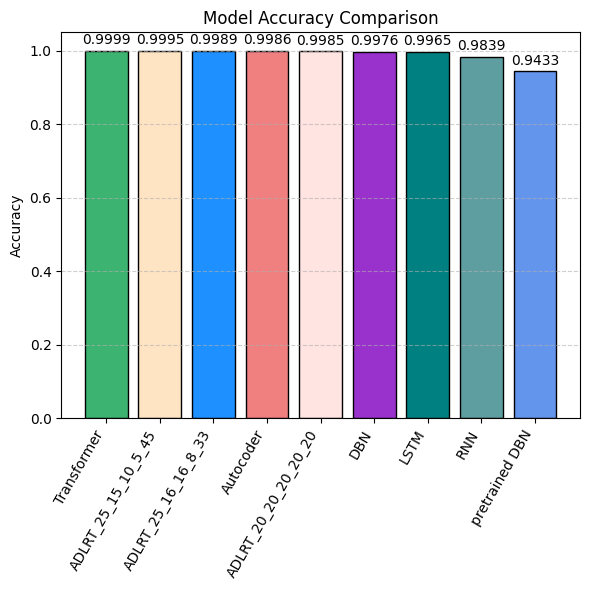

[CACHE DEBUG] Found 'fig' variable with 1 axes
[CACHE] Cached figure from 'fig' variable to: .cache/ensemble_accuracycomp.png
[CACHE] Cached variables: []


In [ ]:
%%cache ensemble_accuracycomp --show

# Final accuracy dictionary (replace with actual last values)

model_accuracies = {
    'Transformer': trans_data["accuracy"][:1].iloc[-1],
    'RNN': rnn_data["accuracy"][:1].iloc[-1],
    'pretrained DBN': predbn["val_accuracy"][1:11].iloc[-1],
    'DBN': dbn_data["accuracy"][:1].iloc[-1],
    'LSTM': lstm_data["accuracy"][:1].iloc[-1],
    'Autocoder': autoencoder_data["accuracy"][:1].iloc[-1],
    "ADLRT_20_20_20_20_20": auto_dbn_lstm_rnn_trans_20_20_20_20_20["accuracy"][:1].iloc[-1],
    "ADLRT_25_16_16_8_33": auto_dbn_lstm_rnn_trans_25_16_16_8_33["accuracy"][:1].iloc[-1],
    "ADLRT_25_15_10_5_45": auto_dbn_lstm_rnn_trans_25_15_10_5_45["accuracy"][:1].iloc[-1]
}

# Sort models by accuracy
sorted_models = sorted(model_accuracies.items(), key=lambda x: x[1], reverse=True)
labels = [name for name,_ in sorted_models]
scores = [acc for _, acc in sorted_models]
colors = [new_colors.get(name, 'gray') for name in labels]
# Plot
fig, ax = plt.subplots(figsize=(6, 6))
bars = ax.bar(labels, scores, color=colors, edgecolor='black')

# Add value labels on top
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.01, f'{height:.4f}',
            ha='center', va='bottom', fontsize=10)

# Styling
ax.set_title('Model Accuracy Comparison')
ax.set_ylabel('Accuracy')
#ax.set_ylim(0, 1.0)
ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.xticks(rotation=60, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

### All metrics compare

[CACHE] Executing cell and caching: ensemble_modelallmetricscomp


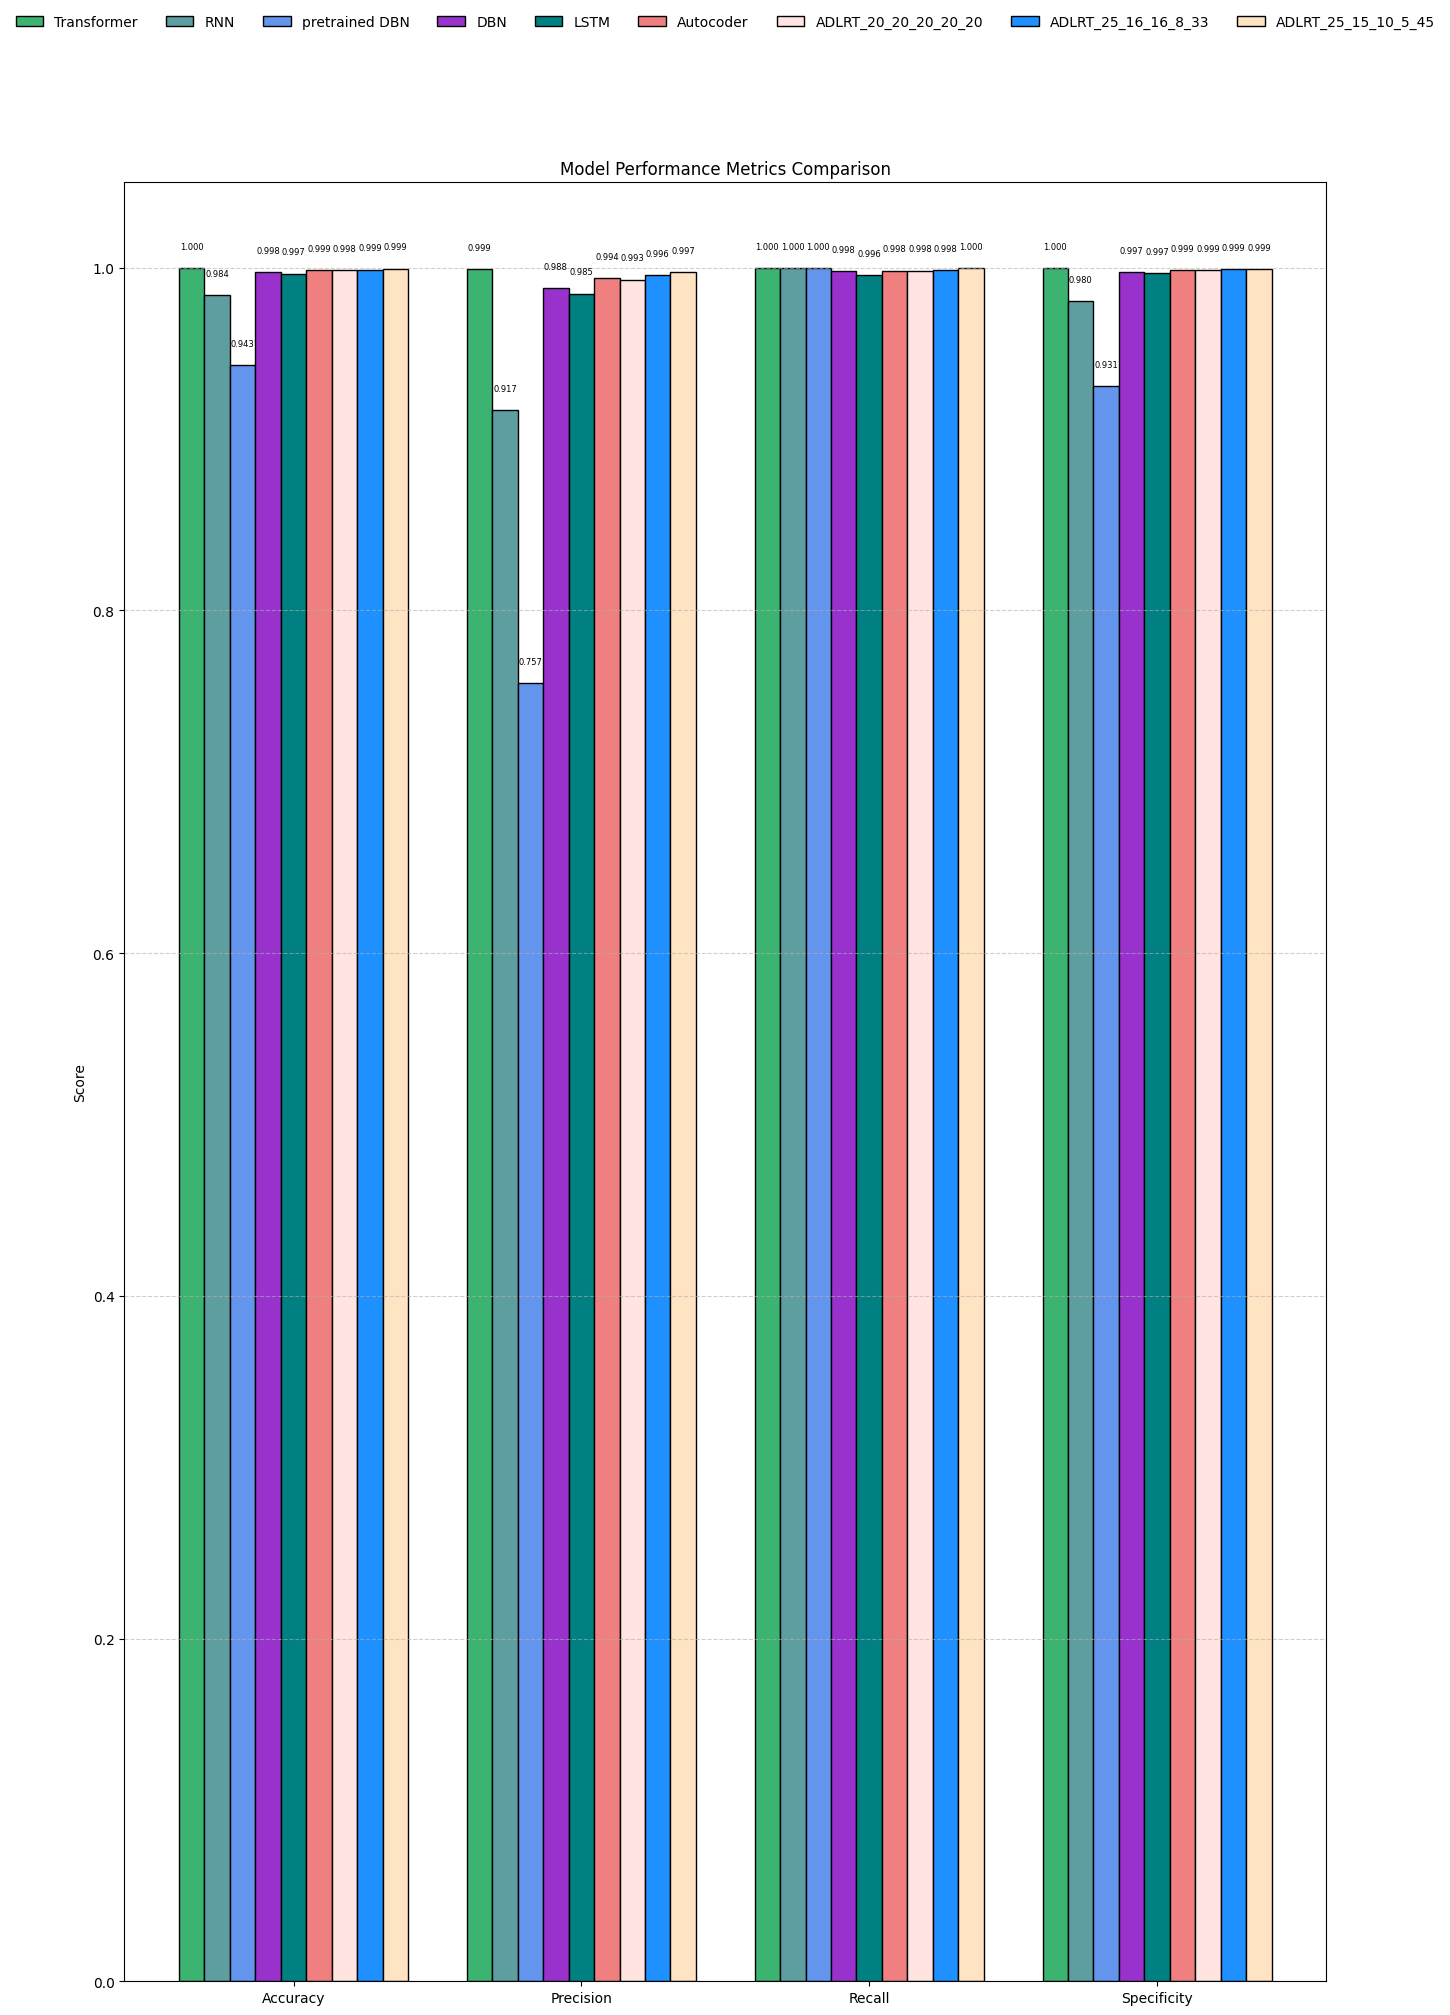

[CACHE DEBUG] Found 'fig' variable with 1 axes
[CACHE] Cached figure from 'fig' variable to: .cache/ensemble_modelallmetricscomp.png
[CACHE] Cached variables: []


In [ ]:

%%cache ensemble_modelallmetricscomp --show

metrics = {
    'Accuracy': {
    'Transformer': trans_data["accuracy"][:1].iloc[-1],
    'RNN': rnn_data["accuracy"][:1].iloc[-1],
    'pretrained DBN': predbn["val_accuracy"][1:11].iloc[-1],
    'DBN': dbn_data["accuracy"][:1].iloc[-1],
    'LSTM': lstm_data["accuracy"][:1].iloc[-1],
    'Autocoder': autoencoder_data["accuracy"][:1].iloc[-1],
    "ADLRT_20_20_20_20_20": auto_dbn_lstm_rnn_trans_20_20_20_20_20["accuracy"][:1].iloc[-1],
    "ADLRT_25_16_16_8_33": auto_dbn_lstm_rnn_trans_25_16_16_8_33["accuracy"][:1].iloc[-1],
    "ADLRT_25_15_10_5_45": auto_dbn_lstm_rnn_trans_25_15_10_5_45["accuracy"][:1].iloc[-1]
    },
    'Precision': {
    'Transformer': trans_data["precision"][:1].iloc[-1],
    'RNN': rnn_data["precision"][:1].iloc[-1],
    'pretrained DBN': predbn["val_precision"][1:11].iloc[-1],
    'DBN': dbn_data["precision"][:1].iloc[-1],
    'LSTM': lstm_data["precision"][:1].iloc[-1],
    'Autocoder': autoencoder_data["precision"][:1].iloc[-1],
    "ADLRT_20_20_20_20_20": auto_dbn_lstm_rnn_trans_20_20_20_20_20["precision"][:1].iloc[-1],
    "ADLRT_25_16_16_8_33": auto_dbn_lstm_rnn_trans_25_16_16_8_33["precision"][:1].iloc[-1],
    "ADLRT_25_15_10_5_45": auto_dbn_lstm_rnn_trans_25_15_10_5_45["precision"][:1].iloc[-1]
    },
    'Recall': {
    'Transformer': trans_data["recall"][:1].iloc[-1],
    'RNN': rnn_data["recall"][:1].iloc[-1],
    'pretrained DBN': predbn["val_recall"][1:11].iloc[-1],
    'DBN': dbn_data["recall"][:1].iloc[-1],
    'LSTM': lstm_data["recall"][:1].iloc[-1],
    'Autocoder': autoencoder_data["recall"][:1].iloc[-1],
    "ADLRT_20_20_20_20_20": auto_dbn_lstm_rnn_trans_20_20_20_20_20["recall"][:1].iloc[-1],
    "ADLRT_25_16_16_8_33": auto_dbn_lstm_rnn_trans_25_16_16_8_33["recall"][:1].iloc[-1],
    "ADLRT_25_15_10_5_45": auto_dbn_lstm_rnn_trans_25_15_10_5_45["recall"][:1].iloc[-1]
    },
    'Specificity': {
    'Transformer': trans_data["specificity"][:1].iloc[-1],
    'RNN': rnn_data["specificity"][:1].iloc[-1],
    'pretrained DBN': predbn["val_specificity"][1:11].iloc[-1],
    'DBN': dbn_data["specificity"][:1].iloc[-1],
    'LSTM': lstm_data["specificity"][:1].iloc[-1],
    'Autocoder': autoencoder_data["specificity"][:1].iloc[-1],
    "ADLRT_20_20_20_20_20": auto_dbn_lstm_rnn_trans_20_20_20_20_20["specificity"][:1].iloc[-1],
    "ADLRT_25_16_16_8_33": auto_dbn_lstm_rnn_trans_25_16_16_8_33["specificity"][:1].iloc[-1],
    "ADLRT_25_15_10_5_45": auto_dbn_lstm_rnn_trans_25_15_10_5_45["specificity"][:1].iloc[-1]

    }
}

# Setup
metric_names = list(metrics.keys())
model_names = list(new_colors.keys())
n_metrics = len(metric_names)
n_models = len(model_names)
bar_width = 0.13
group_spacing = 0.3

# Compute positions
indices = np.arange(n_metrics) * (n_models * bar_width + group_spacing)

fig, ax = plt.subplots(figsize=(15, 20))

# Plot each model's bars, offset within the group
for i, model in enumerate(model_names):
    values = [metrics[metric].get(model, 0) for metric in metric_names]
    positions = indices + i * bar_width
    color = new_colors[model]
    bars = ax.bar(positions, values, width=bar_width, label=model, color=color, edgecolor='black')

    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height + 0.01, f'{height:.3f}',
                ha='center', va='bottom', fontsize=6)

# Label setup
ax.set_title('Model Performance Metrics Comparison')
ax.set_ylabel('Score')
#ax.set_ylim(0, 1.0)

# Set x-ticks to be centered under each group
group_centers = indices + (n_models / 2 - 0.5) * bar_width
ax.set_xticks(group_centers)
ax.set_xticklabels(metric_names)

ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.10), ncol=len(model_names), frameon=False)
ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

[CACHE] Executing cell and caching: ensemble_modelkapf1metricscomp


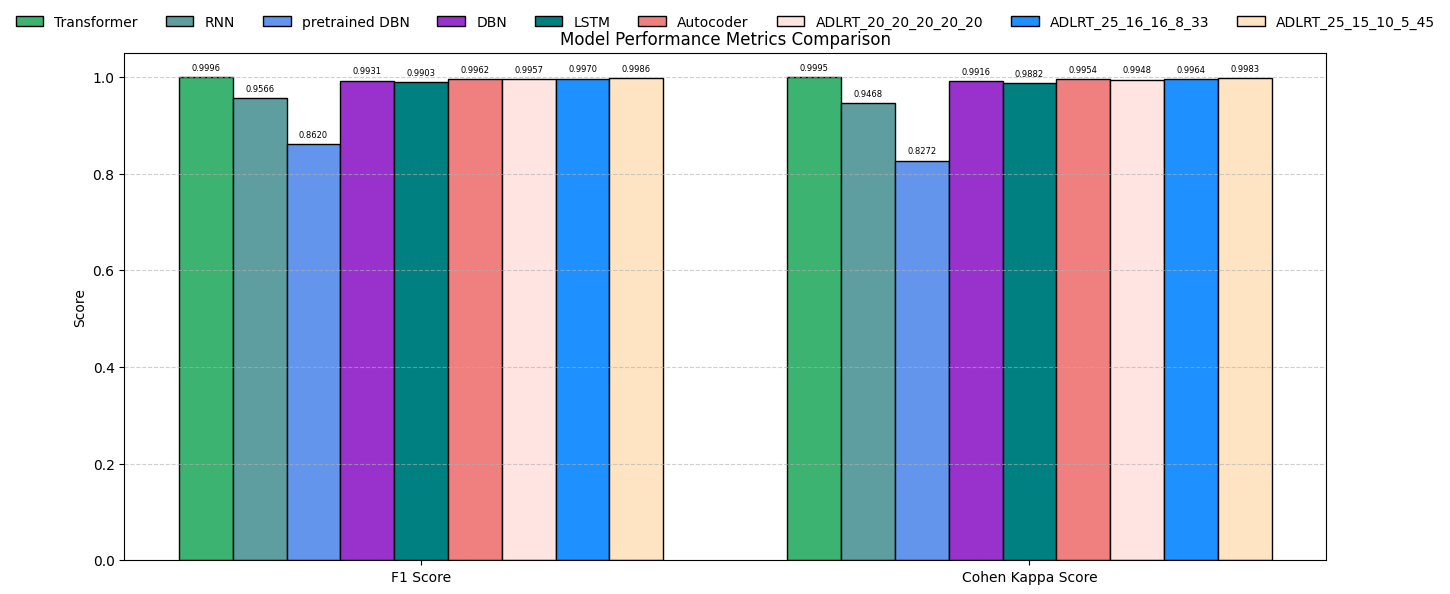

[CACHE DEBUG] Found 'fig' variable with 1 axes
[CACHE] Cached figure from 'fig' variable to: .cache/ensemble_modelkapf1metricscomp.png
[CACHE] Cached variables: []


In [ ]:
%%cache ensemble_modelkapf1metricscomp --show

f1_k_metrics = {
    'F1 Score': {
    'Transformer': trans_data["f1_score"][:1].iloc[-1],
    'RNN': rnn_data["f1_score"][:1].iloc[-1],
    'pretrained DBN': predbn["val_f1_score"][1:11].iloc[-1],
    'DBN': dbn_data["f1_score"][:1].iloc[-1],
    'LSTM': lstm_data["f1_score"][:1].iloc[-1],
    'Autocoder': autoencoder_data["f1_score"][:1].iloc[-1],
    "ADLRT_20_20_20_20_20": auto_dbn_lstm_rnn_trans_20_20_20_20_20["f1_score"][:1].iloc[-1],
    "ADLRT_25_16_16_8_33": auto_dbn_lstm_rnn_trans_25_16_16_8_33["f1_score"][:1].iloc[-1],
    "ADLRT_25_15_10_5_45": auto_dbn_lstm_rnn_trans_25_15_10_5_45["f1_score"][:1].iloc[-1]
    },
    'Cohen Kappa Score': {
    'Transformer': trans_data["cohen_kappa"][:1].iloc[-1],
    'RNN': rnn_data["cohen_kappa"][:1].iloc[-1],
    'pretrained DBN': predbn["val_cohen_kappa"][1:11].iloc[-1],
    'DBN': dbn_data["cohen_kappa"][:1].iloc[-1],
    'LSTM': lstm_data["cohen_kappa"][:1].iloc[-1],
    'Autocoder': autoencoder_data["cohen_kappa"][:1].iloc[-1],
    "ADLRT_20_20_20_20_20": auto_dbn_lstm_rnn_trans_20_20_20_20_20["cohen_kappa"][:1].iloc[-1],
    "ADLRT_25_16_16_8_33": auto_dbn_lstm_rnn_trans_25_16_16_8_33["cohen_kappa"][:1].iloc[-1],
    "ADLRT_25_15_10_5_45": auto_dbn_lstm_rnn_trans_25_15_10_5_45["cohen_kappa"][:1].iloc[-1]

    }
}

# Setup
metric_names = list(f1_k_metrics.keys())
model_names = list(new_colors.keys())
n_metrics = len(metric_names)
n_models = len(model_names)
bar_width = 0.13
group_spacing = 0.3

# Compute positions
indices = np.arange(n_metrics) * (n_models * bar_width + group_spacing)

fig, ax = plt.subplots(figsize=(15, 6))

# Plot each model's bars, offset within the group
for i, model in enumerate(model_names):
    values = [f1_k_metrics[metric].get(model, 0) for metric in metric_names]
    positions = indices + i * bar_width
    color = new_colors[model]
    bars = ax.bar(positions, values, width=bar_width, label=model, color=color, edgecolor='black')

    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height + 0.01, f'{height:.4f}',
                ha='center', va='bottom', fontsize=6)

# Label setup
ax.set_title('Model Performance Metrics Comparison')
ax.set_ylabel('Score')
#ax.set_ylim(0, 1.0)

# Set x-ticks to be centered under each group
group_centers = indices + (n_models / 2 - 0.5) * bar_width
ax.set_xticks(group_centers)
ax.set_xticklabels(metric_names)

ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.10), ncol=len(model_names), frameon=False)
ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()